In [ ]:

# ASSIGNMENT 3 - PART A


In [ ]:
import os, re, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, mean_absolute_error
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42


# Q1

uploaded = files.upload()
a_file = next(
    (f for f in uploaded if "sanjeevani" in f.lower() and f.lower().endswith(".csv")),
    None
)
if a_file is None:
    raise ValueError("Upload sanjeevani_diabetes_screening_raw.csv")

raw = pd.read_csv(a_file, dtype=str, keep_default_na=False)

print("Shape:", raw.shape)
print("Raw column names:")
for c in raw.columns:
    print(repr(c))
for c in ["Sex", "family_history", "HbA1c Result "]:
    if c in raw.columns:
        print(f"\nDistinct {c!r}:")
        print(sorted(raw[c].unique().tolist()))

Saving sanjeevani_diabetes_screening_raw.csv to sanjeevani_diabetes_screening_raw (1).csv
Shape: (3038, 13)
Raw column names:
'Patient ID'
'Camp Location'
'Sex'
'Age'
'family_history'
'height_cm'
'weight_kg'
'BMI'
'waist_cm'
'Daily Steps'
'Blood Pressure'
'total_cholesterol'
'HbA1c Result '

Distinct 'Sex':
['F', 'FEMALE', 'Female', 'M', 'MALE', 'Male', 'female', 'male']

Distinct 'family_history':
['0', '1', 'N', 'No', 'Y', 'Yes', 'no', 'yes']

Distinct 'HbA1c Result ':
['0', '1', 'DIABETIC', 'Negative', 'No', 'Positive', 'Yes', 'normal']


In [ ]:
# Q2

df = raw.copy()
df.columns = [
    re.sub(r"_+", "_",
           re.sub(r"[^a-z0-9]+", "_", c.strip().lower())).strip("_")
    for c in df.columns
]

print(df.columns.tolist())

def clean_text(s):
    return (s.astype(str).str.strip().str.lower()
            .str.replace(r"\s+", " ", regex=True))

df["camp_location"] = clean_text(df["camp_location"]).map({
    "kharghar": "Kharghar", "panvel": "Panvel",
    "vashi": "Vashi", "nerul": "Nerul",
    "thane": "Thane", "dombivli": "Dombivli"
}).fillna(df["camp_location"].str.strip().str.title())

df["sex"] = clean_text(df["sex"]).replace({
    "m": "male", "male": "male",
    "f": "female", "female": "female"
})
print("Camp locations:", sorted(df["camp_location"].unique()))
print("Sex:", sorted(df["sex"].unique()))

['patient_id', 'camp_location', 'sex', 'age', 'family_history', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps', 'blood_pressure', 'total_cholesterol', 'hba1c_result']
Camp locations: ['Dombivli', 'Kharghar', 'Nerul', 'Panvel', 'Thane', 'Vashi']
Sex: ['female', 'male']


In [ ]:
# Q3

def binary(series, positive, negative):
    s = clean_text(series)
    result = pd.Series(np.nan, index=s.index, dtype=float)
    result[s.isin(positive)] = 1
    result[s.isin(negative)] = 0
    return result

df["family_history"] = binary(
    df["family_history"],
    {"yes", "y", "1", "true"},
    {"no", "n", "0", "false"}
)
df["hba1c_result"] = binary(
    df["hba1c_result"],
    {"positive", "yes", "1", "diabetic", "diabetes"},
    {"negative", "no", "0", "normal"}
)


print("Positive rate:", round(df["hba1c_result"].mean(), 4))
print("Positive percentage:", round(df["hba1c_result"].mean()*100, 2), "%")
before = len(df)
df = df.drop_duplicates().copy()
print("Rows before duplicate removal:", before)
print("Rows after duplicate removal:", len(df))
print("Duplicates removed:", before-len(df))
print("Unmapped target rows:", df["hba1c_result"].isna().sum())

Positive rate: 0.2255
Positive percentage: 22.55 %
Rows before duplicate removal: 3038
Rows after duplicate removal: 3000
Duplicates removed: 38
Unmapped target rows: 0


In [ ]:
# Q4

bp = df["blood_pressure"].astype(str).str.strip().str.extract(
    r"^\s*(\d+(?:\.\d+)?)\s*/\s*(\d+(?:\.\d+)?)\s*$"
)
df["systolic"] = pd.to_numeric(bp[0], errors="coerce")
df["diastolic"] = pd.to_numeric(bp[1], errors="coerce")

numeric_cols = [
    "age", "height_cm", "weight_kg", "bmi", "waist_cm",
    "daily_steps", "total_cholesterol"
]
for c in numeric_cols:
    df[c] = pd.to_numeric(
        df[c].astype(str).str.replace(",", "", regex=False)
        .replace({
            "": np.nan, "?": np.nan, "NA": np.nan,
            "na": np.nan, "not measured": np.nan
        }),
        errors="coerce"
    )

print(df[[
    "blood_pressure", "systolic", "diastolic", "daily_steps"
]].head(10).to_string(index=False))

blood_pressure  systolic  diastolic  daily_steps
        102/69     102.0       69.0       8750.0
        106/73     106.0       73.0      12930.0
        136/98     136.0       98.0       6440.0
        114/90     114.0       90.0       4080.0
        124/89     124.0       89.0       4890.0
        110/73     110.0       73.0       8770.0
        123/76     123.0       76.0       7720.0
         90/67      90.0       67.0       2340.0
        137/85     137.0       85.0       4670.0
        114/77     114.0       77.0       8330.0


In [ ]:
# Q5


missing_bmi_idx = df.index[df["bmi"].isna()][:3]
print("Before:")
print(df.loc[missing_bmi_idx, [
    "patient_id", "height_cm", "weight_kg", "bmi"
]].to_string(index=False))

metre_mask = df["height_cm"].between(0.5, 2.5)
print("Heights converted from metres:", int(metre_mask.sum()))
df.loc[metre_mask, "height_cm"] *= 100

height_m = df["height_cm"] / 100
calculated_bmi = df["weight_kg"] / (height_m ** 2)
fill_bmi = df["bmi"].isna() & calculated_bmi.notna()
df.loc[fill_bmi, "bmi"] = calculated_bmi[fill_bmi]

print("After:")
print(df.loc[missing_bmi_idx, [
    "patient_id", "height_cm", "weight_kg", "bmi"
]].to_string(index=False))
print("Interpretation: calculated BMI uses the individual's actual height and weight.")

Before:
patient_id  height_cm  weight_kg  bmi
  SD-22241     177.00       69.9  NaN
  SD-21552       1.56       44.3  NaN
  SD-22406     166.00       67.3  NaN
Heights converted from metres: 45
After:
patient_id  height_cm  weight_kg       bmi
  SD-22241      177.0       69.9 22.311596
  SD-21552      156.0       44.3 18.203485
  SD-22406      166.0       67.3 24.422993
Interpretation: calculated BMI uses the individual's actual height and weight.


In [ ]:
# Q6

bad_age = df["age"].notna() & ~df["age"].between(18, 100)
df.loc[bad_age, "age"] = np.nan
print("IMPOSSIBLE AGES:", int(bad_age.sum()))
print("Missing values by column:")
print(df.isna().sum().sort_values(ascending=False).to_string())

clean_a_path = "/content/sanjeevani_diabetes_screening_cleaned.csv"
df.to_csv(clean_a_path, index=False)
print("Cleaned CSV saved:", clean_a_path)
print("Imputation: median imputation inside the pipeline, fitted on training data only.")

IMPOSSIBLE AGES: 7
Missing values by column:
total_cholesterol    150
waist_cm              90
daily_steps           60
systolic              25
diastolic             25
age                    7
camp_location          0
weight_kg              0
height_cm              0
family_history         0
sex                    0
patient_id             0
bmi                    0
blood_pressure         0
hba1c_result           0
Cleaned CSV saved: /content/sanjeevani_diabetes_screening_cleaned.csv
Imputation: median imputation inside the pipeline, fitted on training data only.


In [ ]:
# Q7

new_waist, new_steps = 98, 6000
visitors = {
    "P1": (76, 6050, 0), "P2": (80, 5980, 0),
    "P3": (101, 7400, 1), "P4": (96, 8000, 1),
    "P5": (106, 4500, 1), "P6": (82, 6100, 0)
}
raw_distances = {}
for name, (w, s, label) in visitors.items():
    dw, ds = w-new_waist, s-new_steps
    d = math.sqrt(dw**2 + ds**2)
    raw_distances[name] = (d, label)
    print(
        f"{name}: sqrt(({w}-98)^2 + ({s}-6000)^2) "
        f"= sqrt({dw**2} + {ds**2}) = {d:.3f}"
    )
nearest_raw = sorted(raw_distances, key=lambda n: raw_distances[n][0])[:3]
raw_vote = sum(raw_distances[n][1] for n in nearest_raw)
print("Nearest 3:", nearest_raw)
print("Prediction:", "Positive" if raw_vote >= 2 else "Negative")
print("Interpretation: raw steps differences dominate because they are much larger numerically than waist differences.")


P1: sqrt((76-98)^2 + (6050-6000)^2) = sqrt(484 + 2500) = 54.626
P2: sqrt((80-98)^2 + (5980-6000)^2) = sqrt(324 + 400) = 26.907
P3: sqrt((101-98)^2 + (7400-6000)^2) = sqrt(9 + 1960000) = 1400.003
P4: sqrt((96-98)^2 + (8000-6000)^2) = sqrt(4 + 4000000) = 2000.001
P5: sqrt((106-98)^2 + (4500-6000)^2) = sqrt(64 + 2250000) = 1500.021
P6: sqrt((82-98)^2 + (6100-6000)^2) = sqrt(256 + 10000) = 101.272
Nearest 3: ['P2', 'P1', 'P6']
Prediction: Negative
Interpretation: raw steps differences dominate because they are much larger numerically than waist differences.


In [ ]:
# Q8

def scale_waist(x):
    return (x-60)/80
def scale_steps(x):
    return x/20000

new_scaled = np.array([scale_waist(98), scale_steps(6000)])
scaled_distances = {}
for name, (w, s, label) in visitors.items():
    point = np.array([scale_waist(w), scale_steps(s)])
    d = np.linalg.norm(point-new_scaled)
    scaled_distances[name] = (d, label)
    print(f"{name}: distance={d:.6f}")
nearest_scaled = sorted(scaled_distances, key=lambda n: scaled_distances[n][0])[:3]
scaled_vote = sum(scaled_distances[n][1] for n in nearest_scaled)
print("Nearest 3:", nearest_scaled)
print("Prediction:", "Positive" if scaled_vote >= 2 else "Negative")
print("Interpretation: scaling makes both measurements comparable; the nearest neighbours can change.")


Q8: MIN-MAX EUCLIDEAN DISTANCE
P1: distance=0.275011
P2: distance=0.225002
P3: distance=0.079412
P4: distance=0.103078
P5: distance=0.125000
P6: distance=0.200062
Nearest 3: ['P3', 'P4', 'P5']
Prediction: Positive
Interpretation: scaling makes both measurements comparable; the nearest neighbours can change.


In [ ]:
# Q9

manhattan = {}
for name, (w, s, label) in visitors.items():
    d = abs(scale_waist(w)-new_scaled[0]) + abs(scale_steps(s)-new_scaled[1])
    manhattan[name] = (d, label)
    print(f"{name}: Manhattan distance={d:.6f}")
nearest_man = sorted(manhattan, key=lambda n: manhattan[n][0])[:3]
man_vote = sum(manhattan[n][1] for n in nearest_man)
print("Nearest 3:", nearest_man)
print("Prediction:", "Positive" if man_vote >= 2 else "Negative")
print("Manhattan prediction changed:", (man_vote >= 2) != (scaled_vote >= 2))
print("Manhattan can be useful when summed absolute differences are more appropriate than squared differences.")



P1: Manhattan distance=0.277500
P2: Manhattan distance=0.226000
P3: Manhattan distance=0.107500
P4: Manhattan distance=0.125000
P5: Manhattan distance=0.175000
P6: Manhattan distance=0.205000
Nearest 3: ['P3', 'P4', 'P5']
Prediction: Positive
Manhattan prediction changed: False
Manhattan can be useful when summed absolute differences are more appropriate than squared differences.


In [ ]:
# Prepare modelling data

model_df = df[df["hba1c_result"].notna()].copy()
numeric_features = [
    "age", "bmi", "waist_cm", "daily_steps",
    "systolic", "diastolic", "total_cholesterol"
]
X_num = model_df[numeric_features].replace([np.inf, -np.inf], np.nan)
y = model_df["hba1c_result"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_num, y, test_size=0.25, random_state=42, stratify=y
)

def classification_metrics(y_true, pred, prob=None):
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob) if prob is not None else np.nan
    }

In [ ]:
# Q10


print("Train rows:", len(X_train), "Test rows:", len(X_test))
print("Train positive rate:", round(y_train.mean(), 4))
print("Test positive rate:", round(y_test.mean(), 4))
baseline_acc = accuracy_score(y_test, np.zeros(len(y_test), dtype=int))
print("Always-negative baseline accuracy:", round(baseline_acc, 4))

Train rows: 2250 Test rows: 750
Train positive rate: 0.2262
Test positive rate: 0.2267
Always-negative baseline accuracy: 0.7733


In [ ]:
# Q11


raw_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
raw_model.fit(X_train, y_train)
pred_raw = raw_model.predict(X_test)
prob_raw = raw_model.predict_proba(X_test)[:, 1]
metrics_raw = classification_metrics(y_test, pred_raw, prob_raw)
print(pd.Series(metrics_raw).round(4))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, pred_raw))
print("Baseline accuracy:", round(baseline_acc, 4))

Accuracy     0.7627
Precision    0.4412
Recall       0.1765
F1           0.2521
ROC-AUC      0.6564
dtype: float64
Confusion matrix [[TN, FP], [FN, TP]]:
[[542  38]
 [140  30]]
Baseline accuracy: 0.7733


In [ ]:
# Q12

scaled_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
scaled_model.fit(X_train, y_train)
pred_scaled = scaled_model.predict(X_test)
prob_scaled = scaled_model.predict_proba(X_test)[:, 1]
metrics_scaled = classification_metrics(y_test, pred_scaled, prob_scaled)

print(pd.DataFrame([
    {"Model": "Raw KNN", **metrics_raw},
    {"Model": "StandardScaler KNN", **metrics_scaled}
]).set_index("Model").round(4).to_string())
print("Feature ranges:")
print(X_train.agg(["min", "max"]).T.to_string())
print("Interpretation: large-range features such as daily_steps can dominate raw distances.")

                    Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                           
Raw KNN               0.7627     0.4412  0.1765  0.2521   0.6564
StandardScaler KNN    0.7880     0.5524  0.3412  0.4218   0.7223
Feature ranges:
                         min      max
age                 21.00000     80.0
bmi                 15.95679     40.6
waist_cm            66.00000    128.0
daily_steps        300.00000  16780.0
systolic            90.00000    173.0
diastolic           55.00000    118.0
total_cholesterol  110.00000    328.0
Interpretation: large-range features such as daily_steps can dominate raw distances.


In [ ]:
# Q13

print("""The imputer and scaler are inside Pipeline:
Pipeline([
 ('imputer', SimpleImputer(strategy='median')),
 ('scaler', StandardScaler()),
 ('knn', KNeighborsClassifier(n_neighbors=5))
])
During fit, medians and scaling parameters are learned from training data only.
Test data is transformed using those same fitted values; it is never used to fit them.""")

The imputer and scaler are inside Pipeline:
Pipeline([
 ('imputer', SimpleImputer(strategy='median')),
 ('scaler', StandardScaler()),
 ('knn', KNeighborsClassifier(n_neighbors=5))
])
During fit, medians and scaling parameters are learned from training data only.
Test data is transformed using those same fitted values; it is never used to fit them.


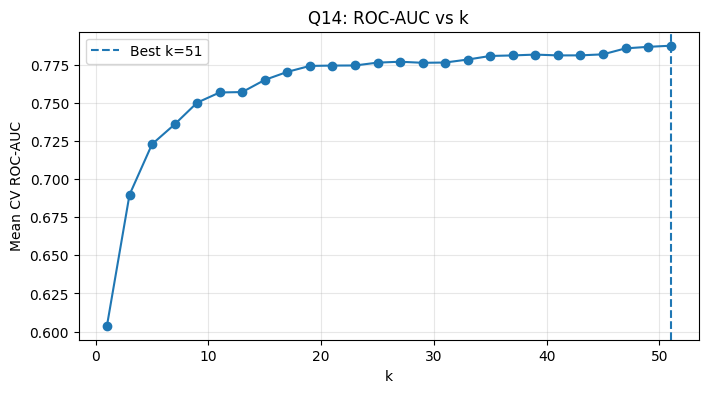

Best k: 51
Best mean CV ROC-AUC: 0.7876
Small k: low bias, high variance. Large k: higher bias and potentially underfits.


In [ ]:
# Q14

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ks = list(range(1, 52, 2))
auc_scores = []
for k in ks:
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(
        pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    auc_scores.append(scores.mean())

best_k14 = ks[int(np.argmax(auc_scores))]
plt.figure(figsize=(8, 4))
plt.plot(ks, auc_scores, marker="o")
plt.axvline(best_k14, linestyle="--", label=f"Best k={best_k14}")
plt.xlabel("k")
plt.ylabel("Mean CV ROC-AUC")
plt.title("Q14: ROC-AUC vs k")
plt.grid(True, alpha=.3)
plt.legend()
plt.show()
print("Best k:", best_k14)
print("Best mean CV ROC-AUC:", round(max(auc_scores), 4))
print("Small k: low bias, high variance. Large k: higher bias and potentially underfits.")

In [ ]:
# Q15

X_all = model_df[numeric_features + ["sex", "family_history"]].copy()
X_all["sex"] = clean_text(X_all["sex"]).replace({"m": "male", "f": "female"})
X_all["family_history"] = X_all["family_history"].map({
    0.0: "no", 1.0: "yes"
}).fillna("unknown")

Xtr, Xte, ytr, yte = train_test_split(
    X_all, y, test_size=.25, random_state=42, stratify=y
)

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", num_pipe, numeric_features),
    ("categorical", cat_pipe, ["sex", "family_history"])
])
tuned_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsClassifier())
])
param_grid = {
    "knn__n_neighbors": list(range(3, 32, 2)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}
grid = GridSearchCV(
    tuned_pipe, param_grid, scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1, refit=True
)
grid.fit(Xtr, ytr)
best_model = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 4))

Best parameters: {'knn__n_neighbors': 29, 'knn__p': 2, 'knn__weights': 'uniform'}
Best CV ROC-AUC: 0.7937


In [ ]:
# Q16


pred16 = best_model.predict(Xte)
prob16 = best_model.predict_proba(Xte)[:, 1]
metrics16 = classification_metrics(yte, pred16, prob16)
print(pd.Series(metrics16).round(4))
cm = confusion_matrix(yte, pred16, labels=[0, 1])
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}: A non-positive visitor is correctly not flagged.")
print(f"FP={fp}: A non-positive visitor is flagged and may use a limited test.")
print(f"FN={fn}: A positive visitor is missed by the model at threshold 0.5.")
print(f"TP={tp}: A positive visitor is correctly flagged.")

Accuracy     0.7987
Precision    0.6863
Recall       0.2059
F1           0.3167
ROC-AUC      0.7807
dtype: float64
Confusion matrix [[TN, FP], [FN, TP]]:
[[564  16]
 [135  35]]
TN=564: A non-positive visitor is correctly not flagged.
FP=16: A non-positive visitor is flagged and may use a limited test.
FN=135: A positive visitor is missed by the model at threshold 0.5.
TP=35: A positive visitor is correctly flagged.


In [ ]:
# Q17

print("For: location may capture real differences in population or camp conditions.")
print("Against: location may proxy socioeconomic/access differences and generalise poorly to new camps.")

For: location may capture real differences in population or camp conditions.
Against: location may proxy socioeconomic/access differences and generalise poorly to new camps.


In [ ]:
# Q18

print("Recall at 0.5:", round(metrics16["Recall"], 4))
print("A 0.5 threshold is not designed for a fixed budget of 250 tests.")
print("Rank by probability and choose the top 250 to match the grant capacity.")

Recall at 0.5: 0.2059
A 0.5 threshold is not designed for a fixed budget of 250 tests.
Rank by probability and choose the top 250 to match the grant capacity.


In [ ]:
# Q19

threshold_rows = []
for th in [.1, .2, .3, .4, .5]:
    p = (prob16 >= th).astype(int)
    tests = int(p.sum())
    found = int(((p == 1) & (yte.to_numpy() == 1)).sum())
    missed = int(((p == 0) & (yte.to_numpy() == 1)).sum())
    threshold_rows.append({
        "Threshold": th,
        "Tests ordered": tests,
        "Diabetics found": found,
        "Diabetics missed": missed,
        "Hit-rate": found/tests if tests else np.nan,
        "Cost per positive (Rs)": 450*tests/found if found else np.nan
    })
threshold_table = pd.DataFrame(threshold_rows)
print(threshold_table.round(3).to_string(index=False))

 Threshold  Tests ordered  Diabetics found  Diabetics missed  Hit-rate  Cost per positive (Rs)
       0.1            537              160                10     0.298                1510.312
       0.2            336              130                40     0.387                1163.077
       0.3            213               97                73     0.455                 988.144
       0.4            116               63               107     0.543                 828.571
       0.5             51               35               135     0.686                 655.714


In [ ]:
# Q20

top_idx = np.argsort(-prob16)[:min(250, len(prob16))]
top250_found = int(yte.iloc[top_idx].sum())
total_positive_test = int(yte.sum())
print("Tests selected:", len(top_idx))
print("Positive cases found:", top250_found)
print("Positive cases in test set:", total_positive_test)
print("Approximate random benchmark from brief:", round(.22*250))
print("Difference from 55 random:", top250_found-55)

Tests selected: 250
Positive cases found: 111
Positive cases in test set: 170
Approximate random benchmark from brief: 55
Difference from 55 random: 56


In [ ]:
# Q21

age_test = model_df.loc[Xte.index, "age"]
sex_test = clean_text(model_df.loc[Xte.index, "sex"])
waist_test = model_df.loc[Xte.index, "waist_cm"]

eyeball = (
    (age_test >= 45) &
    (
        ((sex_test == "male") & (waist_test >= 90)) |
        ((sex_test == "female") & (waist_test >= 80))
    )
).fillna(False).to_numpy()

eyetests = int(eyeball.sum())
eyefound = int(((eyeball) & (yte.to_numpy() == 1)).sum())
print("Eyeball-rule tests:", eyetests)
print("Eyeball-rule positives found:", eyefound)
print("Eyeball-rule total cost Rs:", eyetests*450)
if eyefound:
    print("Eyeball cost per positive Rs:", round(eyetests*450/eyefound, 2))
print("Top-250 model tests:", len(top_idx))
print("Top-250 positives found:", top250_found)
print("Top-250 total cost Rs:", len(top_idx)*450)
if top250_found:
    print("Model cost per positive Rs:", round(len(top_idx)*450/top250_found, 2))

Eyeball-rule tests: 350
Eyeball-rule positives found: 118
Eyeball-rule total cost Rs: 157500
Eyeball cost per positive Rs: 1334.75
Top-250 model tests: 250
Top-250 positives found: 111
Top-250 total cost Rs: 112500
Model cost per positive Rs: 1013.51


In [ ]:
# Q22

chosen_position = int(top_idx[0])
chosen_index = Xte.index[chosen_position]
chosen_visitor = Xte.iloc[[chosen_position]]

pre = best_model.named_steps["preprocessor"]
knn = best_model.named_steps["knn"]
train_transformed = pre.transform(Xtr)
query_transformed = pre.transform(chosen_visitor)
distances, indices = knn.kneighbors(
    query_transformed, n_neighbors=knn.n_neighbors
)
neighbours = Xtr.iloc[indices[0]].copy()
neighbours["actual_HbA1c"] = ytr.iloc[indices[0]].map({
    0: "Negative", 1: "Positive"
}).to_numpy()
neighbours["distance"] = distances[0]
print("Visitor details:")
print(chosen_visitor.to_string(index=False))
print("Predicted positive probability:", round(float(prob16[chosen_position]), 4))
print(neighbours[[
    "age", "bmi", "waist_cm", "daily_steps",
    "sex", "family_history", "actual_HbA1c", "distance"
]].to_string(index=False))
print("Volunteer explanation: Your measurements are similar to those of past visitors who sometimes tested positive.")
print("This is a screening priority, not a diagnosis; the HbA1c test determines your result.")

Visitor details:
 age  bmi  waist_cm  daily_steps  systolic  diastolic  total_cholesterol  sex family_history
69.0 33.6     113.0        590.0     140.0       87.0              243.0 male            yes
Predicted positive probability: 0.8276
 age       bmi  waist_cm  daily_steps    sex family_history actual_HbA1c  distance
55.0 31.000000     112.0       2650.0   male            yes     Positive  1.822484
61.0 32.600000     115.0       1480.0   male             no     Positive  1.877953
66.0 34.446023     119.0       3280.0   male             no     Positive  2.060088
62.0 35.400000     116.0       2420.0 female            yes     Positive  2.377680
66.0 28.000000     102.0        300.0   male            yes     Positive  2.382165
68.0 31.100000     102.0       2010.0   male             no     Positive  2.388446
59.0 31.400000     116.0       2240.0   male             no     Positive  2.438990
64.0 36.600000     117.0       7090.0   male            yes     Positive  2.490045
60.0 26.400

In [ ]:
# Q23

print("\n VISITOR RANKED 260TH")
print("""Weight is only one part of the comparison. The model considers several measurements
together, so two people with the same weight can receive different scores.
Because the grant has a fixed capacity, the ranking prioritises the available tests;
it is not a judgement that someone outside the top 250 is healthy.""")


 VISITOR RANKED 260TH
Weight is only one part of the comparison. The model considers several measurements
together, so two people with the same weight can receive different scores.
Because the grant has a fixed capacity, the ranking prioritises the available tests;
it is not a judgement that someone outside the top 250 is healthy.


In [ ]:
# Q24

summary_rows = []
for name, pred, prob in [
    ("Raw KNN", pred_raw, prob_raw),
    ("Scaled KNN", pred_scaled, prob_scaled),
    ("Tuned KNN", pred16, prob16)
]:
    met = classification_metrics(
        yte if name == "Tuned KNN" else y_test,
        pred, prob
    )
    top = np.argsort(-prob)[:min(250, len(prob))]
    labels_for_model = yte if name == "Tuned KNN" else y_test
    summary_rows.append({
        "Model": name,
        "Accuracy": met["Accuracy"],
        "Recall@0.5": met["Recall"],
        "ROC-AUC": met["ROC-AUC"],
        "Positive in top 250": int(labels_for_model.iloc[top].sum())
    })
print(pd.DataFrame(summary_rows).round(4).to_string(index=False))

     Model  Accuracy  Recall@0.5  ROC-AUC  Positive in top 250
   Raw KNN    0.7627      0.1765   0.6564                   82
Scaled KNN    0.7880      0.3412   0.7223                  104
 Tuned KNN    0.7987      0.2059   0.7807                  111


In [ ]:
# Q25

print(f"""Use the tuned KNN only as a monitored screening-prioritisation aid, not as a diagnosis.
Volunteers can enter the free measurements and offer the limited HbA1c tests to the
highest-ranked visitors, while explaining that a score cannot confirm diabetes.
In this held-out test set, the model finds {top250_found} positive cases in 250 tests,
compared with the assignment brief's approximate random benchmark of 55.
Compare this yield with the measured yield of the age-and-waist rule before claiming
an improvement over current practice.
Monitor performance by age, sex and camp location because the pilot may not represent
all future visitors equally, and keep clinical oversight in the decision process.""")

# Download cleaned CSV
files.download(clean_a_path)

Use the tuned KNN only as a monitored screening-prioritisation aid, not as a diagnosis.
Volunteers can enter the free measurements and offer the limited HbA1c tests to the
highest-ranked visitors, while explaining that a score cannot confirm diabetes.
In this held-out test set, the model finds 111 positive cases in 250 tests,
compared with the assignment brief's approximate random benchmark of 55.
Compare this yield with the measured yield of the age-and-waist rule before claiming
an improvement over current practice.
Monitor performance by age, sex and camp location because the pilot may not represent
all future visitors equally, and keep clinical oversight in the decision process.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>